# Kernel CUDA propio con Numba: augmentation fotométrico

En el modelo CNN2 todo el trabajo de GPU lo hace PyTorch: cuDNN elige los kernels y decide
cuántos hilos y bloques usar. Para diseñar e implementar nosotros el reparto
**hilos → bloques → grid** (pasos 4 y 5 del proyecto), reescribimos una operación del
pipeline como kernels en **CUDA Python con Numba**:

> **Brillo + contraste** del data augmentation de CNN2 (pasos 4 y 5 de `CNN2Augmentation`).
> Se aplica a cada imagen de entrenamiento en cada época: 12,180 imágenes × 3 canales × 64 × 64
> = **150 millones de valores por época**, todos independientes salvo por la media de cada canal.

```
brillo:     y = clamp(x + delta[n], 0, 1)                      delta  ~ U(-0.2, 0.2) por imagen
contraste:  z = clamp((y - media[n,c]) * factor[n] + media[n,c], 0, 1)   factor ~ U(0.8, 1.2)
```

- **Entorno:** `.venv-numba` (Python 3.11.9, Numba 0.61.2, CUDA runtime 12.6), creado con
  `scripts/setup_numba.ps1`. No incluye PyTorch, así que no toca los entornos oficiales.
- **Código:** `src/cuda_kernels/photometric.py`.
- **Medición:** `scripts/benchmark_numba_kernel.py`, con resultados en `results/kernel_numba/`.

## 1. Diseño del algoritmo paralelo

La media de cada canal depende de **todos** sus píxeles ya con el brillo aplicado. Esto crea
una dependencia: el contraste no puede empezar hasta que esté lista la media. CUDA no permite
sincronizar bloques distintos dentro de un mismo kernel, así que el algoritmo se divide en
**dos kernels**. El fin del primero funciona como barrera global.

### Kernel 1: `brightness_mean_kernel` (brillo + reducción)

| Nivel | Qué representa | Tamaño en un batch de 32 |
|---|---|---|
| **Grid** | 1D, un bloque por par (imagen, canal) | `32 × 3 = 96` bloques |
| **Bloque** | 256 hilos que cooperan sobre un canal de 64×64 | 256 hilos |
| **Hilo** | recorre 4096/256 = **16 píxeles** con paso 256, aplica el brillo, escribe y acumula una suma parcial | 16 píxeles |

- Los hilos vecinos leen píxeles contiguos en cada iteración. Así los accesos a memoria
  global se agrupan (*coalesced*): un warp de 32 hilos lee 128 bytes seguidos.
- Las 256 sumas parciales se guardan en **memoria compartida** del bloque y se reducen en
  árbol en `log2(256) = 8` pasos, con `cuda.syncthreads()` entre cada paso. El hilo 0
  escribe la media.

### Kernel 2: `contrast_kernel` (elemento a elemento)

| Nivel | Qué representa | Tamaño en un batch de 32 |
|---|---|---|
| **Grid** | 3D: `(W/16, H/16, N·C)` | `(4, 4, 96)` = 1,536 bloques |
| **Bloque** | mosaico 2D de 16×16 píxeles | 256 hilos |
| **Hilo** | **un píxel** de un canal de una imagen | 1 valor |

En total son `1,536 × 256 = 393,216` hilos, uno por cada valor del batch
(`32·3·64·64`). Los bloques de 256 hilos (8 warps) permiten que cada uno de los 16 SM de la
GTX 1650 (laptop, 1,024 núcleos CUDA) mantenga varios bloques activos a la vez, lo que oculta la latencia de memoria. Si
H o W no fueran múltiplos de 16, la guarda `if y < H and x < W` descarta los hilos
sobrantes.

### Versiones de comparación (misma aritmética)

| Variante | Dónde | Cómo |
|---|---|---|
| `cpu_numpy` | CPU | NumPy vectorizado: cada operación recorre el batch completo y crea temporales |
| `cpu_numba_1hilo` | CPU, 1 núcleo | los mismos bucles compilados con `@njit`: la **versión secuencial** |
| `cpu_numba_paralelo` | CPU, 12 hilos | los mismos bucles con `prange`: un plano (imagen, canal) por hilo de CPU |
| `cuda_con_copias` | GPU | por batch: copia host→device, 2 kernels, copia device→host |
| `cuda_residente` | GPU | la época ya está en la GPU (como en PyTorch, donde el augmentation corre después de copiar el batch): solo kernels |

In [1]:
import inspect
import json
import os
import sys
import warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore", category=Warning, module="numba")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display
from numba import cuda

from src.cuda_kernels import photometric as P

dev = cuda.get_current_device()
print("GPU:", dev.name.decode(), "| compute capability", dev.compute_capability,
      "| SMs:", dev.MULTIPROCESSOR_COUNT, "| máx. hilos/bloque:", dev.MAX_THREADS_PER_BLOCK,
      "| warp:", dev.WARP_SIZE)
print("Configuración de lanzamiento para un batch (32, 3, 64, 64):")
for k, v in P.launch_config((32, 3, 64, 64)).items():
    print(f"  {k:<15} {v}")

GPU: NVIDIA GeForce GTX 1650 | compute capability (7, 5) | SMs: 16 | máx. hilos/bloque: 1024 | warp: 32
Configuración de lanzamiento para un batch (32, 3, 64, 64):
  reduce_grid     (96,)
  reduce_block    (256,)
  contrast_grid   (4, 4, 96)
  contrast_block  (16, 16)


## 2. Código de los kernels

In [2]:
for kernel in (P.brightness_mean_kernel, P.contrast_kernel, P.photometric_gpu):
    fn = getattr(kernel, "py_func", kernel)
    display(Markdown(f"```python\n@cuda.jit\n{inspect.getsource(fn)}```" if fn is not P.photometric_gpu
                     else f"```python\n{inspect.getsource(fn)}```"))

```python
@cuda.jit
@cuda.jit
def brightness_mean_kernel(images, delta, out, means):
    """Un bloque por (imagen, canal). images/out: (N, C, H, W) float32."""
    plane = cuda.blockIdx.x  # índice lineal del par (imagen, canal)
    channels = images.shape[1]
    n = plane // channels
    c = plane % channels
    height = images.shape[2]
    width = images.shape[3]
    pixels = height * width

    tid = cuda.threadIdx.x
    partial = cuda.shared.array(THREADS_PER_BLOCK_REDUCE, dtype=np.float32)

    acc = np.float32(0.0)
    d = delta[n]
    i = tid
    while i < pixels:  # bucle con paso blockDim: hilos vecinos → píxeles vecinos
        y = i // width
        x = i % width
        v = images[n, c, y, x] + d
        v = min(max(v, np.float32(0.0)), np.float32(1.0))
        out[n, c, y, x] = v
        acc += v
        i += cuda.blockDim.x
    partial[tid] = acc
    cuda.syncthreads()

    stride = cuda.blockDim.x // 2  # reducción en árbol en memoria compartida
    while stride > 0:
        if tid < stride:
            partial[tid] += partial[tid + stride]
        cuda.syncthreads()
        stride //= 2

    if tid == 0:
        means[n, c] = partial[0] / pixels
```

```python
@cuda.jit
@cuda.jit
def contrast_kernel(out, factor, means):
    """Un hilo por píxel. grid = (W/16, H/16, N*C), block = (16, 16)."""
    x = cuda.blockIdx.x * cuda.blockDim.x + cuda.threadIdx.x
    y = cuda.blockIdx.y * cuda.blockDim.y + cuda.threadIdx.y
    plane = cuda.blockIdx.z
    channels = out.shape[1]
    n = plane // channels
    c = plane % channels
    if y < out.shape[2] and x < out.shape[3]:  # guarda por si H o W no son múltiplos de 16
        m = means[n, c]
        v = (out[n, c, y, x] - m) * factor[n] + m
        out[n, c, y, x] = min(max(v, np.float32(0.0)), np.float32(1.0))
```

```python
def photometric_gpu(d_images, d_delta, d_factor, d_out, d_means) -> None:
    """Lanza los dos kernels sobre arreglos que ya están en la GPU (sin copiar)."""
    cfg = launch_config(d_images.shape)
    brightness_mean_kernel[cfg["reduce_grid"], cfg["reduce_block"]](
        d_images, d_delta, d_out, d_means
    )
    contrast_kernel[cfg["contrast_grid"], cfg["contrast_block"]](d_out, d_factor, d_means)
```

## 3. Verificación: las cinco versiones dan el mismo resultado

Se usa un batch real de 32 imágenes del split de entrenamiento con los mismos `delta` y
`factor` para todas las versiones. La diferencia contra NumPy debe quedar en el orden del
redondeo de `float32` (~1e-6).

In [3]:
raw = np.load(ROOT / "data" / "X_train.npy", mmap_mode="r")[:32]
batch = np.ascontiguousarray(raw.transpose(0, 3, 1, 2), dtype=np.float32) / 255.0
delta, factor = P.sample_parameters(32, np.random.default_rng(42))

reference = P.photometric_numpy(batch, delta, factor)
outputs = {
    "cpu_numba_1hilo": P.photometric_cpu_sequential(batch, delta, factor),
    "cpu_numba_paralelo": P.photometric_cpu_parallel(batch, delta, factor),
    "cuda (kernels propios)": P.photometric_cuda(batch, delta, factor),
}
check = pd.DataFrame({k: [float(np.abs(v - reference).max())] for k, v in outputs.items()},
                     index=["máx |diferencia| vs NumPy"]).T
display(check)
assert check.values.max() < 1e-5

,máx |diferencia| vs NumPy
cpu_numba_1hilo,5.960464e-07
cpu_numba_paralelo,5.960464e-07
cuda (kernels propios),8.195639e-08


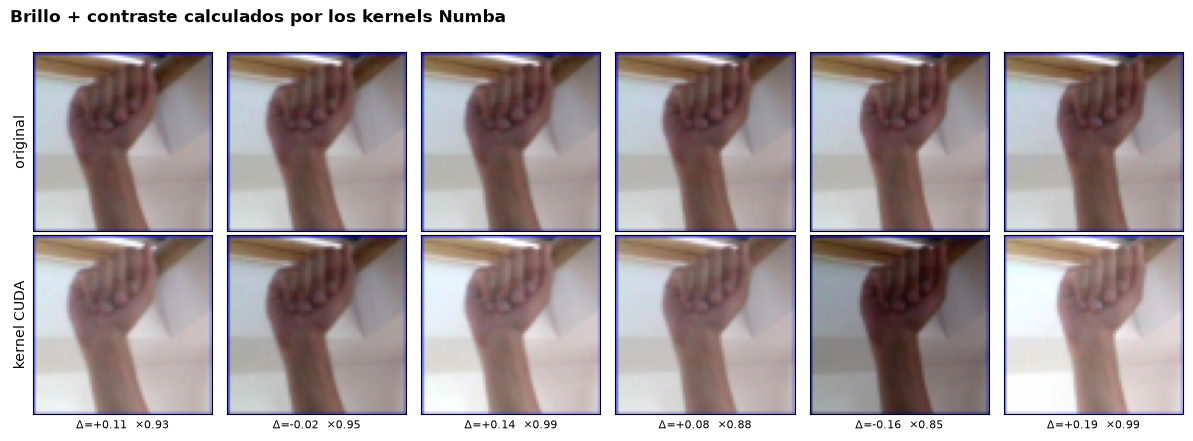

In [4]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4))
for col in range(6):
    axes[0, col].imshow(batch[col].transpose(1, 2, 0))
    axes[1, col].imshow(outputs["cuda (kernels propios)"][col].transpose(1, 2, 0))
    axes[1, col].set_xlabel(f"Δ={delta[col]:+.2f}  ×{factor[col]:.2f}", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].set_ylabel("original")
axes[1, 0].set_ylabel("kernel CUDA")
fig.suptitle("Brillo + contraste calculados por los kernels Numba", x=0.01, ha="left",
             fontweight="bold")
fig.tight_layout()
(ROOT / "reports" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "reports" / "figures" / "07_kernel_ejemplos.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Resultados del benchmark

`scripts/benchmark_numba_kernel.py` procesa **una época completa** (12,180 imágenes) con
cada variante, para 4 tamaños de batch y con 5 repeticiones cada uno. Antes de medir hace
un warm-up que incluye la compilación JIT. En `cuda_con_copias` separa:

- copia host→device (`h2d_s`);
- los dos kernels (`kernel_s`);
- copia device→host (`d2h_s`).

Cada etapa se cierra sincronizando el stream de CUDA. Con el driver 610, `cuda.synchronize()`
de Numba 0.61 falla desde la segunda llamada, pero sincronizar el stream por defecto espera
exactamente lo mismo, porque todo corre en ese stream.

In [5]:
RESULTS = sorted((ROOT / "results" / "kernel_numba").glob("*/results.csv"))[-1]
res = pd.read_csv(RESULTS)
meta = json.loads((RESULTS.parent / "meta.json").read_text(encoding="utf-8"))
print("Resultados:", RESULTS.parent.relative_to(ROOT))
print("Preparación de datos en CPU (uint8 NHWC → float32 NCHW):", f"{meta['prep_cpu_s']:.2f} s")

ORDER = ["cpu_numpy", "cpu_numba_1hilo", "cpu_numba_paralelo", "cuda_con_copias", "cuda_residente"]
NAMES = {
    "cpu_numpy": "CPU NumPy",
    "cpu_numba_1hilo": "CPU secuencial (1 hilo)",
    "cpu_numba_paralelo": "CPU paralelo (12 hilos)",
    "cuda_con_copias": "CUDA con copias CPU↔GPU",
    "cuda_residente": "CUDA, datos en GPU",
}
mean = res.groupby(["batch_size", "variant"])["total_s"].mean().unstack()[ORDER]
std = res.groupby(["batch_size", "variant"])["total_s"].std(ddof=1).unstack()[ORDER]

tabla = mean.rename(columns=NAMES).round(4)
tabla.index.name = "batch"
display(Markdown("**Tiempo medio por época (s), 5 repeticiones**"))
display(tabla)

base = mean["cpu_numba_1hilo"]
speedup = mean.rdiv(base, axis=0)[ORDER].rename(columns=NAMES).round(2)
speedup.index.name = "batch"
display(Markdown("**Speedup respecto a la CPU secuencial (1 hilo)**"))
display(speedup)

tab_dir = ROOT / "reports" / "tablas"
tab_dir.mkdir(parents=True, exist_ok=True)
tabla.to_csv(tab_dir / "kernel_tiempos.csv", encoding="utf-8")
speedup.to_csv(tab_dir / "kernel_speedup_vs_secuencial.csv", encoding="utf-8")

Resultados: results\kernel_numba\20261114T055715Z
Preparación de datos en CPU (uint8 NHWC → float32 NCHW): 0.45 s


**Tiempo medio por época (s), 5 repeticiones**

variant,CPU NumPy,CPU secuencial (1 hilo),CPU paralelo (12 hilos),CUDA con copias CPU↔GPU,"CUDA, datos en GPU"
batch,,,,,
32,2.2615,0.5632,0.5491,1.5502,0.2912
128,1.8209,0.4259,0.4156,0.6303,0.0639
512,1.7750,0.4622,0.2102,0.5299,0.0276
2048,1.4964,0.4093,0.1787,0.3947,0.0271


**Speedup respecto a la CPU secuencial (1 hilo)**

variant,CPU NumPy,CPU secuencial (1 hilo),CPU paralelo (12 hilos),CUDA con copias CPU↔GPU,"CUDA, datos en GPU"
batch,,,,,
32,0.25,1.0,1.03,0.36,1.93
128,0.23,1.0,1.02,0.68,6.67
512,0.26,1.0,2.20,0.87,16.72
2048,0.27,1.0,2.29,1.04,15.09


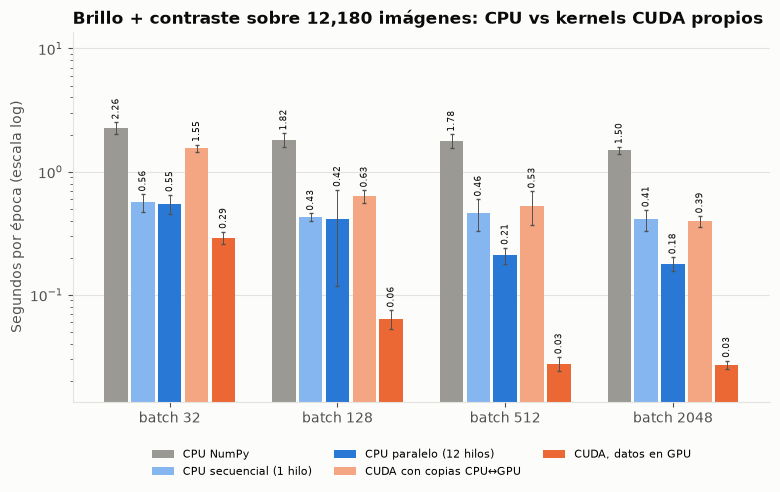

In [6]:
COLORS = {
    "cpu_numpy": "#9a9994", "cpu_numba_1hilo": "#86b6ef", "cpu_numba_paralelo": "#2a78d6",
    "cuda_con_copias": "#f4a582", "cuda_residente": "#eb6834",
}
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 10, "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "xtick.color": INK_2, "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False,
})

fig, ax = plt.subplots(figsize=(9, 4.8))
batches = list(mean.index)
x = np.arange(len(batches))
w = 0.16
for i, v in enumerate(ORDER):
    bars = ax.bar(x + (i - 2) * w, mean[v], w - 0.02, yerr=std[v], color=COLORS[v],
                  label=NAMES[v], error_kw={"ecolor": INK_2, "elinewidth": 0.7, "capsize": 1.5})
    ax.bar_label(bars, fmt="%.2f", padding=2, fontsize=6.5, color=INK, rotation=90)
ax.set_yscale("log")
ax.set_xticks(x, [f"batch {b}" for b in batches])
ax.set_ylabel("Segundos por época (escala log)")
ax.set_title("Brillo + contraste sobre 12,180 imágenes: CPU vs kernels CUDA propios")
ax.grid(axis="x", visible=False)
ax.set_ylim(mean.values.min() * 0.5, mean.values.max() * 6)
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.1))
fig.savefig(ROOT / "reports" / "figures" / "08_kernel_tiempos.png", dpi=200, bbox_inches="tight")
plt.show()

### ¿A dónde se va el tiempo en CUDA con copias?

,h2d_s,kernel_s,d2h_s,h2d_s %,kernel_s %,d2h_s %
batch_size,,,,,,
32,1.0726,0.2092,0.2672,69.2,13.5,17.3
128,0.3885,0.0979,0.1436,61.7,15.5,22.8
512,0.2579,0.1343,0.1377,48.7,25.3,26.0
2048,0.1620,0.1327,0.1000,41.0,33.6,25.3


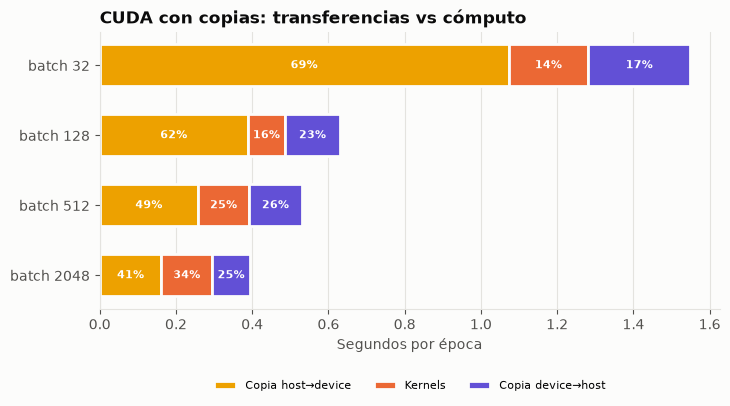

In [7]:
cc = res[res.variant == "cuda_con_copias"].groupby("batch_size")[["h2d_s", "kernel_s", "d2h_s"]].mean()
cc_pct = 100 * cc.div(cc.sum(axis=1), axis=0)
display(pd.concat([cc.round(4), cc_pct.round(1).add_suffix(" %")], axis=1))

PARTS = {"h2d_s": ("Copia host→device", "#eda100"), "kernel_s": ("Kernels", "#eb6834"),
         "d2h_s": ("Copia device→host", "#6250d6")}
fig, ax = plt.subplots(figsize=(8, 3.6))
y = np.arange(len(cc.index))
left = np.zeros(len(cc.index))
for col, (label, color) in PARTS.items():
    ax.barh(y, cc[col], 0.6, left=left, color=color, edgecolor=SURFACE, linewidth=2, label=label)
    for yi, (l, v, p) in enumerate(zip(left, cc[col], cc_pct[col])):
        if p >= 12:
            ax.text(l + v / 2, yi, f"{p:.0f}%", ha="center", va="center", color="white",
                    fontsize=8, fontweight="bold")
    left += cc[col].values
ax.set_yticks(y, [f"batch {b}" for b in cc.index])
ax.invert_yaxis()
ax.set_xlabel("Segundos por época")
ax.set_title("CUDA con copias: transferencias vs cómputo")
ax.grid(axis="y", visible=False)
ax.legend(ncol=3, fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.22))
fig.savefig(ROOT / "reports" / "figures" / "09_kernel_desglose_copias.png", dpi=200, bbox_inches="tight")
plt.show()

## 5. Interpretación

1. **El cómputo en GPU sí es mucho más rápido.** Con la época ya en la GPU y batches
   grandes, los kernels procesan 150 M valores en unos 0.03 s, un orden de magnitud por
   debajo de la CPU secuencial y varias veces por debajo de la CPU con todos sus núcleos.
2. **Las copias CPU↔GPU deciden el resultado.** Esta operación hace muy poco cálculo por
   byte (unas cuantas sumas y multiplicaciones por píxel). Copiar cada batch por PCIe y
   traerlo de vuelta cuesta más que calcularlo, así que `cuda_con_copias` queda al nivel de la
   CPU paralela o por debajo. Por eso en el pipeline real el augmentation se hace **en la GPU,
   después** de copiar el batch una sola vez para la red, y el resultado nunca vuelve a la CPU.
3. **Con batches pequeños domina el costo de lanzar kernels.** En batch 32 hay 381 batches ×
   2 kernels = 762 lanzamientos, cada uno con un costo fijo de Python/Numba y del driver. Con
   batch 2048 son solo 12, y la GPU se aprovecha mejor (más bloques simultáneos para sus 16
   SM). Esto explica también por qué en el benchmark de PyTorch las fases pequeñas (loss,
   métricas) salen más lentas en CUDA que en CPU.
4. **La CPU paralela supera a NumPy** porque recorre cada plano una sola vez sin crear
   arreglos temporales, y reparte los 96 planos (imagen, canal) de un batch entre los 12 hilos
   lógicos.

Conclusión: CUDA conviene para operaciones con **mucho cálculo por dato** (convoluciones:
forward 10.4× y backward 5.8× en el benchmark de CNN2), o cuando los datos **ya están** en la
GPU. Para operaciones ligeras con datos en la CPU, la transferencia anula la ganancia.